# TP2 - Séries temporelles, de la visualisation à l'interprétation

**NOM : Patron PRENOM : Antoine**

Pour rappel un enchainement de code ne vaut pas réponse. Toute question attend une ou des portions de codes ET des analyses écrites.

Sans écrit pas de point.

In [13]:
# Compléter ici les imports des modules utiles
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

## Q1- importer le jeu de données et analyser les données disponibles puis utiles.

**Lecture de données et formalisation du temps.**

la librairie pandas permet de manipuler le temps notamment à travers les fonctions :

 - datetime :
 - set_index
 - strftime

Voici pour rappel une documentation associée :</br>
https://docs.python.org/fr/3/library/datetime.html

In [14]:
# Importer les donnees d'éclairage public (issues du data.gouv.fr)
# à compléter
df = pd.read_csv("eclairage-public.csv")

In [15]:
#vérifier l'importation
print("Ce dataframe contient",df.shape[0],"lignes et",df.shape[1],"colones.")
print(df.head(5))

Ce dataframe contient 4354 lignes et 9 colones.
            Région    Département    Ville     CP  \
0  Hauts-de-France  Pas-de-Calais  Béthune  62400   
1  Hauts-de-France  Pas-de-Calais  Béthune  62400   
2  Hauts-de-France  Pas-de-Calais  Béthune  62400   
3  Hauts-de-France  Pas-de-Calais  Béthune  62400   
4  Hauts-de-France  Pas-de-Calais  Béthune  62400   

               Bâtiment ou Rue        Date  Consommation (kWhEN)  \
0  1 RUE DU PRESIDENT COTY 014  2017-01-01           2477.727648   
1  1 RUE DU PRESIDENT COTY 014  2017-02-01           2237.938560   
2  1 RUE DU PRESIDENT COTY 014  2017-03-01           2477.727648   
3  1 RUE DU PRESIDENT COTY 014  2017-04-01           2397.803760   
4  1 RUE DU PRESIDENT COTY 014  2017-05-01           2477.727648   

   Coût (€ TTC)  Emission GES (kgCO2)  
0    292.328917            208.128269  
1    264.037961            187.986068  
2    292.328917            208.128269  
3    282.899284            201.414690  
4    292.328917         

Nous disposont d'un jeu de donnée contenant 4354 lignes et 9 colones.

In [16]:
# verifier la sortie de la fonction describe - que remarquez-vous ? 
print(df.describe())

            CP  Consommation (kWhEN)  Coût (€ TTC)  Emission GES (kgCO2)
count   4354.0           4354.000000   4354.000000           4354.000000
mean   62400.0           1362.498043    175.370911            114.448393
std        0.0           1703.853920    180.551142            143.123540
min    62400.0         -20292.918260  -1594.420943          -1704.605134
25%    62400.0            310.551265     60.078153             26.084519
50%    62400.0           1039.671464    137.386290             87.331361
75%    62400.0           1995.481522    249.180410            167.617798
max    62400.0          23273.265015   2342.180678           1954.954261


Constat : On peut remarquer que seulement 4 colones apparaissent avec describe. Les colones qui apparaissent sont celle qui contiennent des nombres.</br>
On peut remarquer qu'il n'y a pas l'air d'y avoir de donnée nulle dans le dataframe.</br></br>
On peut cepandant remarquer la presance de données qui pourrait paraitre incoherante dans ce contexte pour le min, car il est *a priori* impossible d'avoir une consommation negative. Cela peut cepandant être expliqué par la presence d'une centrale produisant de l'electricitée dans cette ville, ou d'autres equipements produisant de l'electricitée qui est injectée dans le reseau.

In [17]:
# rechercher ici toutes les colonnes ayant un unique élement
# df.nunique() étudier la sortie
print(df.nunique())

Région                     1
Département                1
Ville                      1
CP                         1
Bâtiment ou Rue          128
Date                      36
Consommation (kWhEN)    3698
Coût (€ TTC)            3854
Emission GES (kgCO2)    3701
dtype: int64


In [18]:
# Retirer les colonnes avec un seul élément unique
df=df.drop(columns="Région")
df=df.drop(columns="Département")
df=df.drop(columns="Ville")
df=df.drop(columns="CP")
print(df.head(5))

               Bâtiment ou Rue        Date  Consommation (kWhEN)  \
0  1 RUE DU PRESIDENT COTY 014  2017-01-01           2477.727648   
1  1 RUE DU PRESIDENT COTY 014  2017-02-01           2237.938560   
2  1 RUE DU PRESIDENT COTY 014  2017-03-01           2477.727648   
3  1 RUE DU PRESIDENT COTY 014  2017-04-01           2397.803760   
4  1 RUE DU PRESIDENT COTY 014  2017-05-01           2477.727648   

   Coût (€ TTC)  Emission GES (kgCO2)  
0    292.328917            208.128269  
1    264.037961            187.986068  
2    292.328917            208.128269  
3    282.899284            201.414690  
4    292.328917            208.128269  


## Q2- Retrouver la date et la rendre interprétable

In [19]:
# transformer la date en format date interprétable et la mettre en index
df['IndexDate'] = pd.to_datetime(df['Date'])
df.set_index('IndexDate', inplace=True)
df=df.drop(columns="Date")

# vérifier
print(df.head(5))

                        Bâtiment ou Rue  Consommation (kWhEN)  Coût (€ TTC)  \
IndexDate                                                                     
2017-01-01  1 RUE DU PRESIDENT COTY 014           2477.727648    292.328917   
2017-02-01  1 RUE DU PRESIDENT COTY 014           2237.938560    264.037961   
2017-03-01  1 RUE DU PRESIDENT COTY 014           2477.727648    292.328917   
2017-04-01  1 RUE DU PRESIDENT COTY 014           2397.803760    282.899284   
2017-05-01  1 RUE DU PRESIDENT COTY 014           2477.727648    292.328917   

            Emission GES (kgCO2)  
IndexDate                         
2017-01-01            208.128269  
2017-02-01            187.986068  
2017-03-01            208.128269  
2017-04-01            201.414690  
2017-05-01            208.128269  


Grace a la fonction to_datetime de panda, il est possible de convertir un texte en date.

## Q3- Dessiner la consommation moyenne par mois quelque soit l'adresse. Comment évolue cette consommation d'après ce graphe ?

            Consommation (kWhEN)
2017-01-01           1773.015483
2017-02-01           1615.510014
2017-03-01           1787.654785
2017-04-01           1567.927771
2017-05-01           1393.669725
2017-06-01           1271.639556
2017-07-01           1243.815869
2017-08-01           1243.320669
2017-09-01           1280.768252


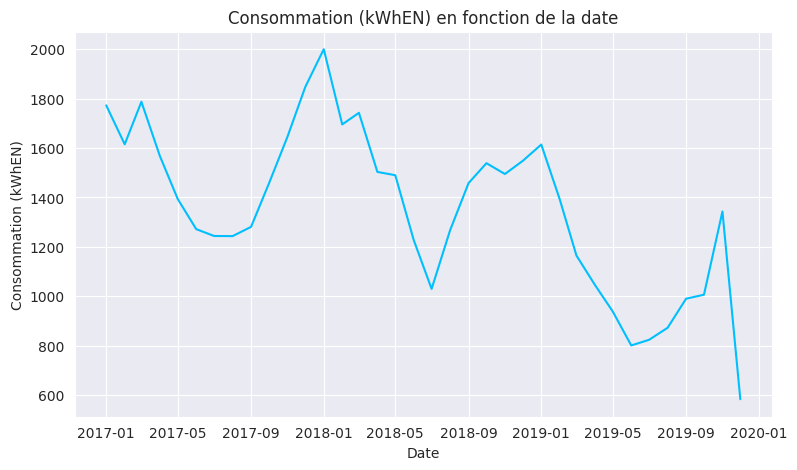

In [20]:
# Regrouper les données par jour et calculez la consommation moyenne mensuelle
# groupby - mean
df_conso = df.drop(columns="Bâtiment ou Rue")
df_conso = df_conso.drop(columns="Coût (€ TTC)")
df_conso = df_conso.drop(columns="Emission GES (kgCO2)")
g = df_conso.groupby([df_conso.index.date]).mean()
#verifier que c'est un dataframe avec index de temps sinon refaire la transformation
print(g.head(9))
"""conso = pd.DataFrame({'Date': df_conso.index, 'conso': df_conso.values})
conso['Date'] = pd.to_datetime(conso['Date'])
conso.set_index('Date', inplace=True)
print(conso.head())"""

# Créer un graphique pour afficher la consommation moyenne par mois
plt.figure(figsize=(9,5))
plt.plot(g,color="deepskyblue")
plt.xlabel("Date")
plt.ylabel("Consommation (kWhEN)")
plt.title("Consommation (kWhEN) en fonction de la date")
plt.grid(True)
plt.show()

On peut observer un cycle qui a l'air de se repeter d'année en année, avec un pic de consomation qui se dessine en janvier. On peut egalement observer que la consomatio globale a l'air d'être en baisse.

## Q4- Les années se ressemblent-elles ?

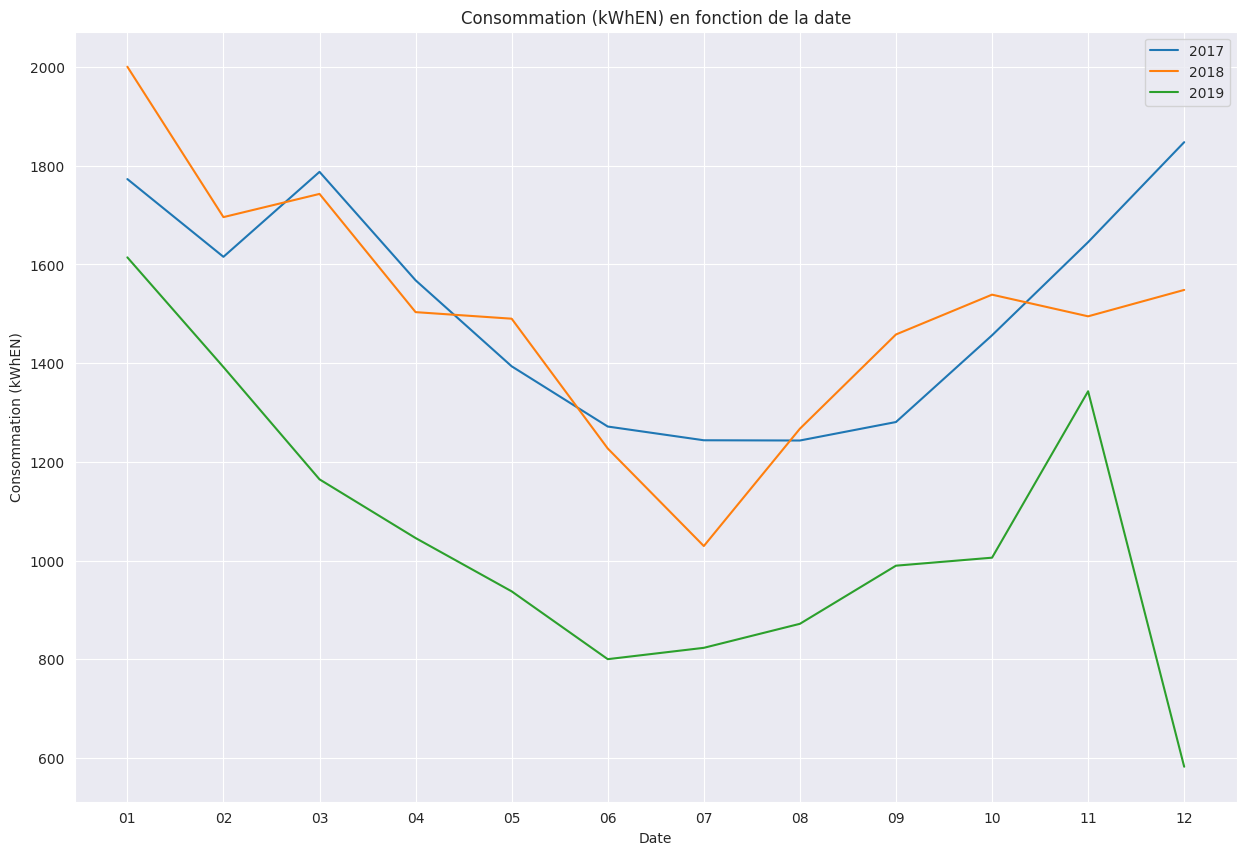

'conso = df.groupby(df.index.date)["Consommation (kWhEN)"].mean()\nprint(conso.head())\n\nconso = pd.DataFrame({\'Date\': conso.index, \'conso\': conso.values})\nconso[\'Date\'] = pd.to_datetime(conso[\'Date\'])\nconso.set_index(\'Date\', inplace=True)\nprint(conso.head())\n\nplt.figure(figsize=(15, 10))\nfor annee in range(df_conso.index.min().year, df_conso.index.max().year + 1):\n    conso_annee = df_conso[df_conso.index.year == annee]\n    plt.plot(range(len(conso_annee)), conso_annee.values, label=f\'Conso {annee}\')\nplt.legend(loc=("best"))\nplt.title(\'Courbes de consomation par annee\')\nplt.show()'

In [21]:
# tracer un graphe avec pour abscisses les mois, et en ordonnée la conso. 
# superposer chaque année avec une legende
df_conso = df.drop(columns="Bâtiment ou Rue")
df_conso = df_conso.drop(columns="Coût (€ TTC)")
df_conso = df_conso.drop(columns="Emission GES (kgCO2)")
df_conso = df_conso.groupby([df_conso.index.date]).mean()

df_conso['IndexDate'] = pd.to_datetime(df_conso.index)
df_conso.set_index('IndexDate', inplace=True)

df_conso['year'] = df_conso.index.year
df_conso['numMonth'] = [d.strftime('%m') for d in df_conso.index]
years = df_conso['year'].unique()

plt.figure(figsize=(15,10))

for i, y in enumerate(years):
    plt.plot("numMonth", "Consommation (kWhEN)", data=df_conso.loc[df_conso.year==y, :], label=y)

plt.xlabel("Date")
plt.ylabel("Consommation (kWhEN)")
plt.title("Consommation (kWhEN) en fonction de la date")
plt.legend(loc="upper right")
plt.grid(True)
plt.show()

"""conso = df.groupby(df.index.date)["Consommation (kWhEN)"].mean()
print(conso.head())

conso = pd.DataFrame({'Date': conso.index, 'conso': conso.values})
conso['Date'] = pd.to_datetime(conso['Date'])
conso.set_index('Date', inplace=True)
print(conso.head())

plt.figure(figsize=(15, 10))
for annee in range(df_conso.index.min().year, df_conso.index.max().year + 1):
    conso_annee = df_conso[df_conso.index.year == annee]
    plt.plot(range(len(conso_annee)), conso_annee.values, label=f'Conso {annee}')
plt.legend(loc=("best"))
plt.title('Courbes de consomation par annee')
plt.show()"""

On peut observer que les année 2017 et 2018 sont trés similaires, avec quasiment les même pics et creux. On peut observer ensuite observer que l'année 1019 a une allure similaire, a l'exeption de decembre. On peut egalement voir que la consomation globale est plus faible que pour les deux années precedante.

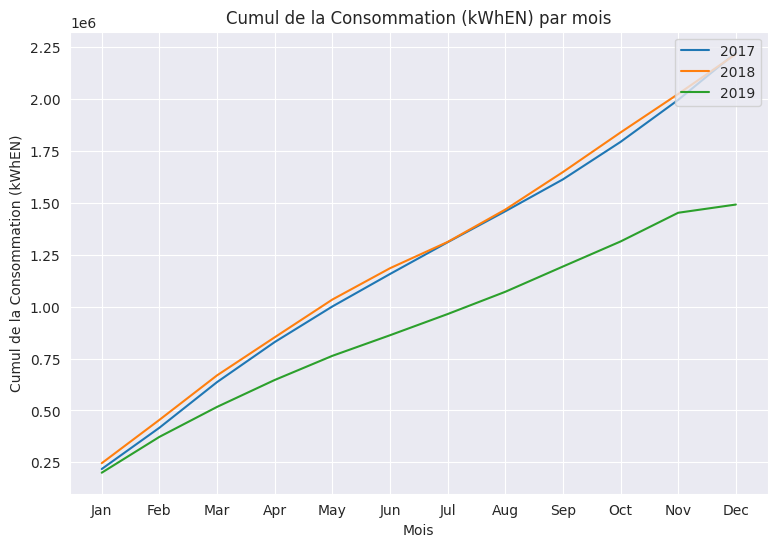

'consoCumul = df.groupby(df.index.date)["Consommation (kWhEN)"].cumsum()\n\nconsoCumul = pd.DataFrame({\'Date\': consoCumul.index, \'conso\': consoCumul.values})\nconsoCumul[\'Date\'] = pd.to_datetime(consoCumul[\'Date\'])\nconsoCumul.set_index(\'Date\', inplace=True)\n\nplt.figure(figsize=(8,8))\nfor annee in range(consoCumul.index.min().year, consoCumul.index.max().year+1):\n    consoC_annee = consoCumul[consoCumul.index.year == annee]\n    plt.plot(range(len(consoC_annee)), consoC_annee.values, label=f\'Conso {annee}\')\nplt.legend(loc=\'best\')\nplt.title(\'Courbes cumulees des consomation par annee\')\nplt.show()'

In [22]:
# Courbes avec cumul de la conso par année

# Supprimer les colonnes inutiles et regrouper par année et mois
df_conso = df.drop(columns=["Bâtiment ou Rue", "Coût (€ TTC)", "Emission GES (kgCO2)"])
df_conso['Date'] = pd.to_datetime(df_conso.index)
df_conso.set_index('Date', inplace=True)

# Aggrégation par année et mois
df_conso['Year'] = df_conso.index.year
df_conso['Month'] = df_conso.index.month
df_conso_grouped = df_conso.groupby(['Year', 'Month']).sum()

# Réinitialiser l'index pour avoir Year et Month en colonnes
df_conso_grouped.reset_index(inplace=True)

# Créer un dictionnaire pour mapper les numéros de mois aux noms de mois
month_names = {1: 'Jan', 2: 'Feb', 3: 'Mar', 4: 'Apr', 5: 'May', 6: 'Jun', 7: 'Jul', 8: 'Aug', 9: 'Sep', 10: 'Oct', 11: 'Nov', 12: 'Dec'}

# Remplacer les numéros de mois par les noms de mois
df_conso_grouped['Month'] = df_conso_grouped['Month'].map(month_names)

# Créer le graphique
plt.figure(figsize=(9,6))

years = df_conso_grouped['Year'].unique()

for y in years:
    data = df_conso_grouped[df_conso_grouped['Year'] == y]
    cumsum = data['Consommation (kWhEN)'].cumsum()  # Calcul du cumul de la consommation
    plt.plot(data['Month'], cumsum, label=str(y))

plt.xlabel("Mois")
plt.ylabel("Cumul de la Consommation (kWhEN)")
plt.title("Cumul de la Consommation (kWhEN) par mois")
plt.legend(loc="upper right")
plt.grid(True)
plt.show()


"""consoCumul = df.groupby(df.index.date)["Consommation (kWhEN)"].cumsum()

consoCumul = pd.DataFrame({'Date': consoCumul.index, 'conso': consoCumul.values})
consoCumul['Date'] = pd.to_datetime(consoCumul['Date'])
consoCumul.set_index('Date', inplace=True)

plt.figure(figsize=(8,8))
for annee in range(consoCumul.index.min().year, consoCumul.index.max().year+1):
    consoC_annee = consoCumul[consoCumul.index.year == annee]
    plt.plot(range(len(consoC_annee)), consoC_annee.values, label=f'Conso {annee}')
plt.legend(loc='best')
plt.title('Courbes cumulees des consomation par annee')
plt.show()"""

On peut observer que les années 2017 et 2018 sont trés similaires, et augmentent principalement en debut et fin d'année. La courbe de 2019, quand a elle, presente une consomation bien moins importante, avec, en fin d'année, une differance de pres de 0.75 kWhEN.
## Q5 - La serie conso est-elle stationnaire ? verifier matematiquement.

In [23]:
from statsmodels.tsa.stattools import adfuller

df_conso = df.drop(columns="Bâtiment ou Rue")
df_conso = df_conso.drop(columns="Coût (€ TTC)")
df_conso = df_conso.drop(columns="Emission GES (kgCO2)")
g = df_conso.groupby([df_conso.index.date]).mean()

result = adfuller(g)

adf_stat = result[0]
p_value = result[1]
critical_values = result[4]

print(adf_stat)
print(p_value)
print("Critical values : ")
for key, value in critical_values.items():
    print(key, ":", value)

2.429551983458535
0.9990235453521457
Critical values : 
1% : -3.6996079738860943
5% : -2.9764303469999494
10% : -2.627601001371742


Grace au resultat de adfuller, et notamment a la p value, on peut conclure que la serie n'est pas stationnaire, et subie une certaine saisonalité.
## Q6 - La consommation à Béthune a-t-elle un cycle, une tendance ? Les résidus sont-ils importants.

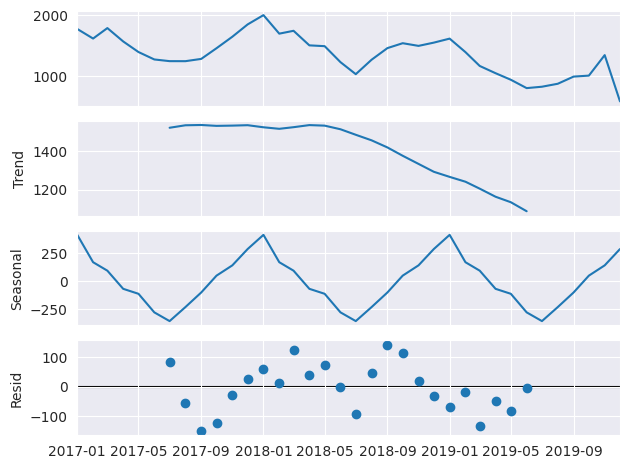

In [24]:
# from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.seasonal import seasonal_decompose

conso = df.groupby(df.index.date)["Consommation (kWhEN)"].mean()

conso = pd.DataFrame({'Date': conso.index, 'conso': conso.values})
conso['Date'] = pd.to_datetime(conso['Date'])
conso.set_index('Date', inplace=True)

res = seasonal_decompose(conso, model='additive')
resplot = res.plot()

Grace a seasonal_decompose, on peut observer que la consomation a bethune suit un cycle saisonier annuel plutot marque, avec une forte tendance a la baisse a partir d'environ septembre 2018. On peut egalement observer que des residus sont present sur environ 3/4 du signal, et que ceux ci sont compris dans un interval qui semble plutot restraint.

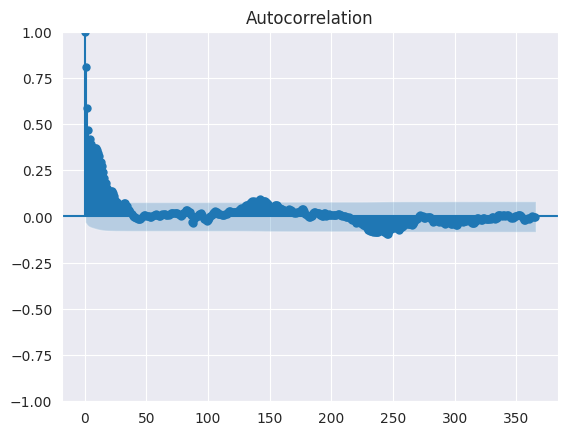

In [25]:
# from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.graphics.tsaplots import plot_acf
x=plot_acf(df_conso,lags=365)

Grace a l'auto-corellation avec un decalage d'une annee, on peut voir qu'une majeure partie des données est comprise dans l'intervalle bleu, ce qui signifie que les residus detecter precedament ne sont que du bruit.
## Q7- Vos conclusions sur les consommations mensuelles sont-elles vraies pour chaque armoire (lieu) ? Se dessinent-ils des comportements identiques entres les armoires de mesure ?

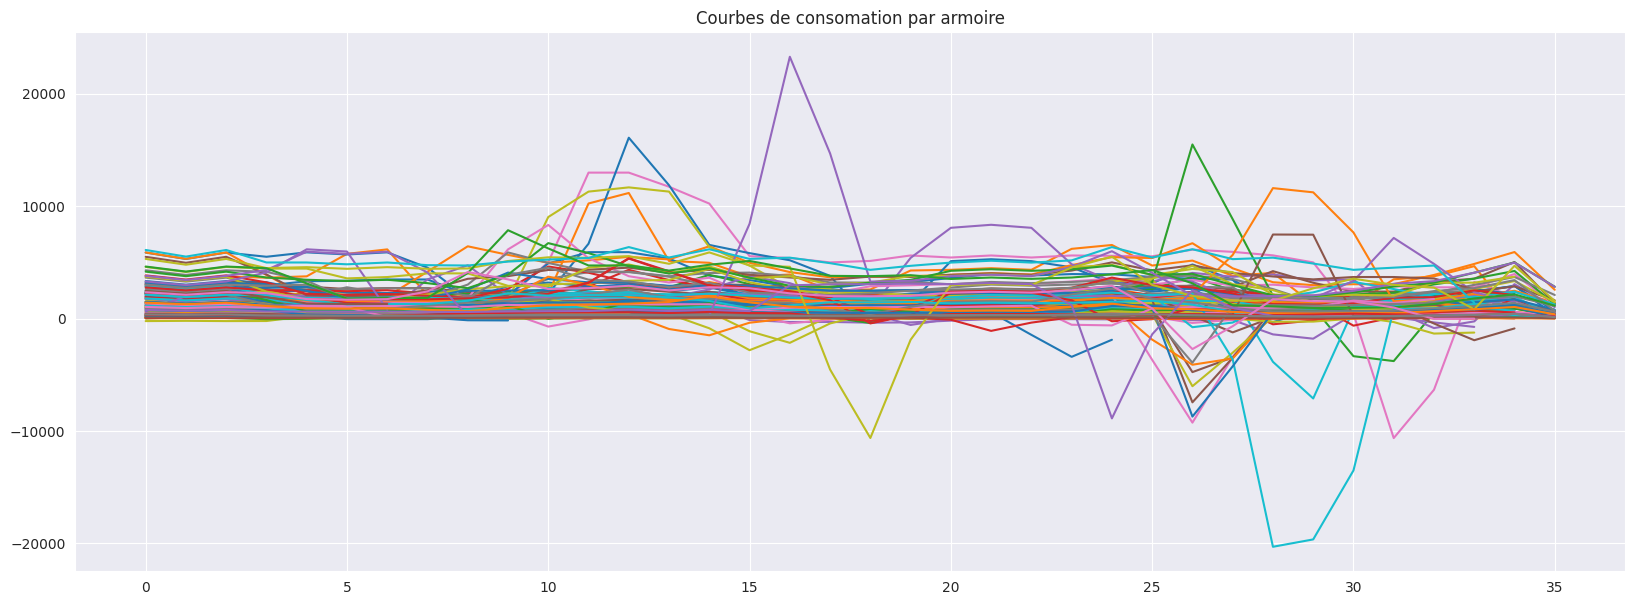

In [26]:
plt.figure(figsize=(20, 7))
for armoire in df["Bâtiment ou Rue"].unique():
    conso_armoire= df[df["Bâtiment ou Rue"] == armoire]
    plt.plot(range(len(conso_armoire)), conso_armoire["Consommation (kWhEN)"].values)
plt.title('Courbes de consomation par armoire')
plt.show()

On peut observer lors de la visualisation par amoire qu'une majoritee est situee dans le meme groupe, mais qu'une partie des armoires suit un comportement beaucoup plus heratique.